In [1]:
   import networkx as nx
   import numpy as np
   import matplotlib.pyplot as plt
   import scipy
   import pandas as pd
   import os
   import pickle
   import json
   import warnings
   import pandas as pd
   import random
   import powerlaw
   import graph_tool.all as gt
   import time

   from scipy.io import mmread
   from collections import Counter
   from tailestim import HillEstimator, MomentsEstimator, KernelTypeEstimator

   print("networkx", nx.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__)

networkx 3.5 | numpy 2.3.3 | scipy 1.16.2


   # NETS/PHYS 7052 — Assignment 02
   Jacopo Conti, Fall 2026

### Use of AI
I used Claude (Anthropic). I ran and tested all the code myself, and the explanations are my own.

- **Question 1 (AI-Forbidden):** Unfortunalty, my lnowledge of both the syntax and the logic of python is still not autosufficient. For this reason, despite the label, I used AI only as a tool to understand the questions: to clarify what was being asked and to guide my reasoning step by step, without receiving answers or code. All code has ben rewritten; results, and explanations are my own.
- **Question 2 (AI-Limited):** I used AI for debugging and documentation help only.
- **Question 3 (AI-Permitted):** I used Claude (Anthropic) as a helper for code suggestions in 3.b.iv and for designing the parameter sweep in 3.c. I ran and tested all the code, and the written explanations are my own.
- **Question 4 (AI-Encouraged):** I used Claude as a learning partner to structure the package, write the README, and push the repository to GitHub. I tested the installation myself in a fresh environment.

## Question 1 — Fitting power-law degree distributions

### 01.a.

In [2]:
N = 10000

m = 4

# Initial sitaution : fully connected graph wioth 4 nodes (each degree = 3)
list_edges = [(0,1),(0,2),(0,3),(1,2),(1,3),(2,3)] # List of edges (6) in the initial graph
targets_pool = [] # A list of nodes to which the new node can connect. Picking uniformly from this list = picking a node with probability k_i / sum(k)
for a, b in list_edges: # where a and b are the two endpoints of each edge, we add both endpoints to the pool
    targets_pool.append(a)
    targets_pool.append(b)
print("Initial graph edges:", list_edges)
print("Targets pool:", targets_pool)

# Now, let's add a new node
new_node = 4
chosen = set() # an empty set ignores duplicates, so we get m distinct targets
while len(chosen) < m: # we repeat until we have m distinct targets
    chosen.add(random.choice(targets_pool)) # we p[ick randomly from the pool (P(k_i) = k_i / sum(k))]
print(chosen)

# Now, let's update each new link (new_node, target) adds both endpoints to the pool
for target in chosen: # we loop over the targets we just chose and add the new edges to the graph
    targets_pool.append(new_node)
    targets_pool.append(target)
    list_edges.append((new_node, target))

print("Chosen targets:", chosen)
print("Updated pool:", targets_pool)
print("Length:", len(targets_pool)) # check that the length of the pool is now 12 + 2 * m = 20

Initial graph edges: [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
Targets pool: [0, 1, 0, 2, 0, 3, 1, 2, 1, 3, 2, 3]
{0, 1, 2, 3}
Chosen targets: {0, 1, 2, 3}
Updated pool: [0, 1, 0, 2, 0, 3, 1, 2, 1, 3, 2, 3, 4, 0, 4, 1, 4, 2, 4, 3]
Length: 20


In [3]:
# Now let's add growth and checkpoints for the snapshots

N = 10000                          
m = 4

checkpoints = [10**2, 10**3, 10**4] # checkpoints for the degree sequence
snapshots = {} # dictionary where to save for later to plot

# Initial complete graph
list_edges = [(0,1),(0,2),(0,3),(1,2),(1,3),(2,3)]
targets_pool = []                  
for a, b in list_edges:
    targets_pool.append(a)
    targets_pool.append(b)

# Growth: add nodes 4, 5, ..., N-1
for new_node in range(4, N):# one iteration = one new node
    chosen = set()                 
    while len(chosen) < m:
        chosen.add(random.choice(targets_pool))  

    for target in chosen: # add the m new links
        targets_pool.append(new_node)
        targets_pool.append(target)
        list_edges.append((new_node, target))

    if new_node + 1 in checkpoints:
        snapshots[new_node + 1] = list(Counter(targets_pool).values())

print("Number of links:", len(list_edges))    
print("Pool length:", len(targets_pool))      

Number of links: 39990
Pool length: 79980


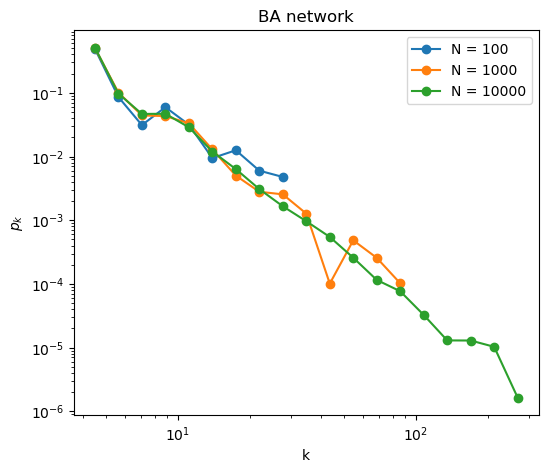

In [4]:
# Now let's log bin

k_min = m
k_max = max(snapshots[10**4])
bins = np.logspace(np.log10(k_min), np.log10(k_max), num=20) #20 edges → 19 bins, equally spaced in log scale

fig, ax = plt.subplots(figsize=(6, 5))

for n, degs in snapshots.items(): # one curve per snapshot
    pk, edges = np.histogram(degs, bins=bins, density=True) # desnity = dividing by total count and bin width > estimate of p_k
    centers = np.sqrt(edges[:-1] * edges[1:]) # geometric bin centers
    mask = pk > 0 # drop empty bins
    ax.plot(centers[mask], pk[mask], 'o-', label=f'N = {n}')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('k')
ax.set_ylabel('$p_k$')
ax.set_title('BA network')
ax.legend()
plt.show()

### 1.b

1. Fit in one single snapshot with powerlaw and read y and k_min
2. Repeat for the three snapshot and put them in the legend
3. interpret witht he exact formula

In [5]:
fit = powerlaw.Fit(snapshots[10**4], discrete=True)
print("gamma:", fit.alpha)
print("k_min:", fit.xmin)

Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 100/100 [00:00<00:00, 1145.72it/s]

gamma: 2.8471435546874995
k_min: 9.0


Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 15/15 [00:00<00:00, 1139.30it/s]


Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 43/43 [00:00<00:00, 1471.60it/s]


Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 100/100 [00:00<00:00, 1191.54it/s]


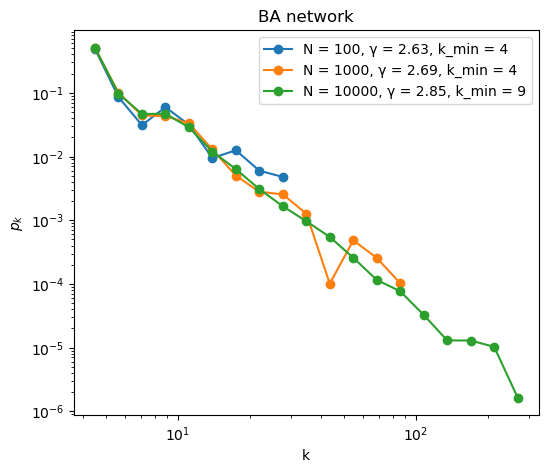

In [6]:
k_min = m
k_max = max(snapshots[10**4])
bins = np.logspace(np.log10(k_min), np.log10(k_max), num=20)
fits = {}

fig, ax = plt.subplots(figsize=(6, 5))

for n, degs in snapshots.items():
    fit = powerlaw.Fit(degs, discrete=True)
    fits[n] = fit

    pk, edges = np.histogram(degs, bins=bins, density=True)
    centers = np.sqrt(edges[:-1] * edges[1:])
    mask = pk > 0
    ax.plot(centers[mask], pk[mask], 'o-',  label=f'N = {n}, γ = {fit.alpha:.2f}, k_min = {fit.xmin:.0f}')   # fit results in the legend

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('k')
ax.set_ylabel('$p_k$')
ax.set_title('BA network')
ax.legend()
plt.show()

My estimation approaches 3 as the network grows. For k >>> 0, k+1 or k+2 is ≈ k (approximation). Therefore, the denominator is k^3. However, for k <<< 0 this changes. The straight line representing the exact formula, in our log-log graph, changes the slope accordingly with k. We can calculate the local slope on each point of the line as well. Bigger networks have enough nodes to allow a k_min with a greater value, where the exact formula resembles more a k^-3. But however, this will always be less than 3.

### 1.c

Growing an ensemble of 100 BA networks.
One network could give a lucky or unlucky result, so I grow 100 BA networks (N = 10⁴, m = 4), each with a different random seed, and save their degree sequences.

In [7]:
N = 10000                          
m = 4

saved_networks = []

for i in range (100):
    random.seed(i) # random.seed(i) = different seed for each network
    list_edges = [(0,1),(0,2),(0,3),(1,2),(1,3),(2,3)]
    targets_pool = []                  
    for a, b in list_edges:
        targets_pool.append(a)
        targets_pool.append(b)

    for new_node in range(4, N): 
        chosen = set()                 
        while len(chosen) < m:
            chosen.add(random.choice(targets_pool))  

        for target in chosen:
            targets_pool.append(new_node)
            targets_pool.append(target)
            list_edges.append((new_node, target))

    saved_networks.append(list(Counter(targets_pool).values()))

print(len(saved_networks))
print(len(saved_networks[0]))     

100
10000


Estimating γ with powerlaw. I apply the same method as in (b) to all 100 networks and store the estimated γ for each one.

In [8]:
gammas = [] # empty list to store the 100 γ estimates

for degs in saved_networks: # go through each of the 100 networks
    fit = powerlaw.Fit(degs, discrete=True, verbose=False) # fit a power law
    gammas.append(fit.alpha)

print(gammas[:5]) # quick check: show the first 5 values

[np.float64(2.8655273437499993), np.float64(2.8624511718749996), np.float64(2.7995361328124995), np.float64(2.8566650390624995), np.float64(2.829052734375)]


Estimating γ with the Hill, moments, and kernel-type estimators. I estimate γ again with three estimators from tailestim, which choose the tail differently from powerlaw, so I can compare all four methods on the same networks.

In [9]:
gammas_hill = [] # gammas from the Hill estimator
gammas_moments = [] # gammas from the moments estimator
gammas_kernel = [] # gammas from the kernel-type estimator

for degs in saved_networks:   # go through each of the 100 networks
    hill = HillEstimator()
    hill.fit(degs)
    gammas_hill.append(hill.get_result().gamma_)

    moments = MomentsEstimator()
    moments.fit(degs)
    gammas_moments.append(moments.get_result().gamma_)

    kernel = KernelTypeEstimator()
    kernel.fit(degs)
    gammas_kernel.append(kernel.get_result().gamma_)

print(gammas_hill[:5])
print(gammas_moments[:5])
print(gammas_kernel[:5])

/Users/jac/anaconda3/envs/cnet5051/lib/python3.11/site-packages/tailestim/estimators/tail_methods.py:193: RuntimeWarning: invalid value encountered in divide
  | (np.abs(1.0 - (M1**2) / M2) < 1e-10)
/Users/jac/anaconda3/envs/cnet5051/lib/python3.11/site-packages/tailestim/estimators/tail_methods.py:194: RuntimeWarning: invalid value encountered in divide
  | (np.abs(1.0 - (M1 * M2) / M3) < 1e-10)
/Users/jac/anaconda3/envs/cnet5051/lib/python3.11/site-packages/tailestim/estimators/tail_methods.py:193: RuntimeWarning: divide by zero encountered in divide
  | (np.abs(1.0 - (M1**2) / M2) < 1e-10)
/Users/jac/anaconda3/envs/cnet5051/lib/python3.11/site-packages/tailestim/estimators/tail_methods.py:907: RuntimeWarning: invalid value encountered in divide
  xi_arr = gamma_pos - 1.0 + q2 / q1
/Users/jac/anaconda3/envs/cnet5051/lib/python3.11/site-packages/tailestim/estimators/tail_methods.py:976: RuntimeWarning: invalid value encountered in divide
  xi_arr = gamma_pos - 1.0 + q2 / q1
/Users/jac

[np.float64(2.7914301276610693), np.float64(2.785166245596346), np.float64(2.7887422056719746), np.float64(2.786261623046504), np.float64(2.7922151997871696)]
[np.float64(2.995461485491501), np.float64(2.958110666486103), np.float64(2.9744869935436924), np.float64(2.9583894997303917), np.float64(2.9696862731518507)]
[np.float64(2.960797609660778), np.float64(2.92369592412745), np.float64(2.9174153495214608), np.float64(2.9327697959533525), np.float64(2.9407633419650336)]


Comparing the spread of the four estimators. I plot the 100 estimates of each method side by side, with a dashed line at γ = 3, the value predicted by the BA model.

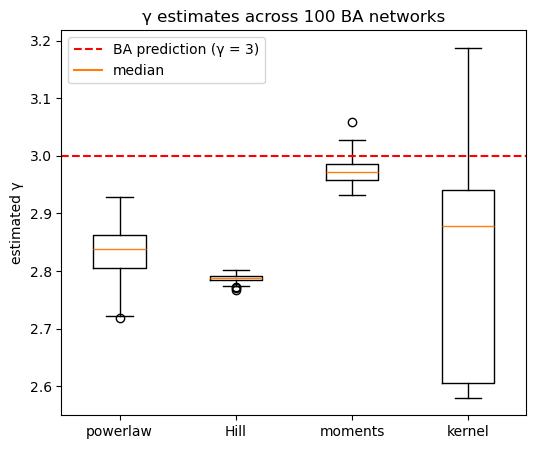

In [10]:
all_gammas = [gammas, gammas_hill, gammas_moments, gammas_kernel]   # the four lists of 100 estimates
names = ['powerlaw', 'Hill', 'moments', 'kernel']  # labels for the x-axis

fig, ax = plt.subplots(figsize=(6, 5))
ax.boxplot(all_gammas, tick_labels=names) # one box per estimator
ax.axhline(3, color='red', linestyle='--', label='BA prediction (γ = 3)') # reference line
ax.plot([], [], color='C1', label='median') # empty line, only to show the median color in the legend
ax.set_ylabel('estimated γ')
ax.set_title('γ estimates across 100 BA networks')
ax.legend()
plt.show()

Mean and standard deviation of each estimator. The mean tells us whether an estimator is biased (systematically far from 3), and the standard deviation tells us how much it varies between networks.

In [11]:
for name, values in zip(names, all_gammas): # go through each estimator with its name
    print(name, 'mean =', round(np.mean(values), 3), 'std =', round(np.std(values), 3))

powerlaw mean = 2.832 std = 0.044
Hill mean = 2.787 std = 0.006
moments mean = 2.973 std = 0.022
kernel mean = 2.796 std = 0.182


Across the 100 networks the four estimators behave quite differently.

powerlaw gives γ = 2.832 ± 0.044, and almost all the values are below 3. This is the same bias we saw in (b): the fit uses all degrees above a small k_min, and for small k the exact formula has a local slope smaller than 3, so the estimate is pulled down.

Hill is the most precise estimator (its box is very narrow, but it is also clearly biased: it gives almost the same value for every network, and that value is below 3.

Moments is the only estimator that really recovers γ = 3. Its median is very close to 3 and the spread is small.

Kernel has a median a bit below 3 (around 2.9), but its spread is very large, from about 2.6 to 3.2. On average it is not far from 3, but on a single network it is not reliable.

In short: moments recovers γ = 3, powerlaw and Hill are biased downward, and kernel is centered close to 3 but very noisy.

Power law vs lognormal. For each network I compare a power law with a lognormal using powerlaw’s likelihood-ratio test, to see whether the test recognizes networks that I know were grown by preferential attachment.

In [12]:
Rs = [] # likelihood ratios (one per network)
ps = [] # p-values (one per network)

for degs in saved_networks: # go through each of the 100 networks
    fit = powerlaw.Fit(degs, discrete=True, verbose=False)
    R, p = fit.distribution_compare('power_law', 'lognormal')   # compare the two distributions
    Rs.append(R)
    ps.append(p)

print(Rs[:5])
print(ps[:5])

/Users/jac/anaconda3/envs/cnet5051/lib/python3.11/site-packages/powerlaw/distributions.py:743: OptimizeWarning: Initial guess is not within the specified bounds
  result = scipy.optimize.minimize(fit_function,
/Users/jac/anaconda3/envs/cnet5051/lib/python3.11/site-packages/powerlaw/distributions.py:743: OptimizeWarning: Initial guess is not within the specified bounds
  result = scipy.optimize.minimize(fit_function,
/Users/jac/anaconda3/envs/cnet5051/lib/python3.11/site-packages/powerlaw/distributions.py:743: OptimizeWarning: Initial guess is not within the specified bounds
  result = scipy.optimize.minimize(fit_function,
/Users/jac/anaconda3/envs/cnet5051/lib/python3.11/site-packages/powerlaw/distributions.py:743: OptimizeWarning: Initial guess is not within the specified bounds
  result = scipy.optimize.minimize(fit_function,
/Users/jac/anaconda3/envs/cnet5051/lib/python3.11/site-packages/powerlaw/distributions.py:743: OptimizeWarning: Initial guess is not within the specified bounds

[np.float64(-0.23624455485477291), np.float64(-0.06518728907584315), np.float64(-1.682090474833588), np.float64(-0.025248392943818754), np.float64(-0.6917680213922317)]
[np.float64(0.6709708019086729), np.float64(0.8405423058546019), np.float64(0.3307395894431864), np.float64(0.899363019594404), np.float64(0.5207785027349408)]


/Users/jac/anaconda3/envs/cnet5051/lib/python3.11/site-packages/powerlaw/distributions.py:743: OptimizeWarning: Initial guess is not within the specified bounds
  result = scipy.optimize.minimize(fit_function,
/Users/jac/anaconda3/envs/cnet5051/lib/python3.11/site-packages/powerlaw/distributions.py:743: OptimizeWarning: Initial guess is not within the specified bounds
  result = scipy.optimize.minimize(fit_function,


In [13]:
pl_wins = sum(1 for R, p in zip(Rs, ps) if R > 0 and p < 0.1) # count networks where the power law is clearly favored (R > 0, significant p)   
ln_wins = sum(1 for R, p in zip(Rs, ps) if R < 0 and p < 0.1) # count networks where the lognormal is clearly favored (R < 0, significant p)
undecided = 100 - pl_wins - ln_wins # all the other networks                           

print('power law favored:', pl_wins)
print('lognormal favored:', ln_wins)
print('inconclusive:', undecided)

power law favored: 0
lognormal favored: 4
inconclusive: 96


For each network I compared a power law with a lognormal using the likelihood-ratio test. The power law was favored in 0 networks, the lognormal in 4, and in the other 96 the result was inconclusive (p ≥ 0.1). Most values of R are negative, so the test leans slightly toward the lognormal, even though we know these networks were grown by preferential attachment and should have γ = 3.

Basically, the test cannot recognize a power law even when we know it is there. With a finite network the tail is short, and for small k the distribution is curved (as we saw in (b)), so a lognormal can fit the data almost as well. An inconclusive or lognormal result does not mean that a network is not scale-free. We should be careful when using this test on real networks, where we don’t know the mechanism.

### 1.d

Voitalov, I., van der Hoorn, P., van der Hofstad, R., & Krioukov, D. (2019). Scale-free networks well done.
Physical Review Research, 1(3), 033034. doi: 10.1103/PhysRevResearch.1.033034.

Broido, A. D., & Clauset, A. (2019). Scale-free networks are rare. Nature Communications, 10(1), 1017.
doi: 10.1038/s41467-019-08746-5.

Broido & Clauset define a network as scale-free if its degree distribution follows a pure power law, Pr(k) ∝ k^(−α), at least in the upper tail, so for k ≥ k_min (p. 2). If below k_min the distribution can look like anything, but above it should look like a power law. They then organize different versions of this definition into categories of evidence, from "Super-Weak" to "Strongest" (p. 3–4). Alternatively, Voitalov et al. instead define a scale-free network as one whose degree distribution is regularly varying: P(k) = ℓ(k) · k^(−γ), where ℓ(k) is a slowly varying function, meaning a function that can change, but so slowly that for k → ∞ it doesn't matter anymore (p. 3–4). So the distribution doesn't need to be an exact power law anywhere, it only needs to behave like one for very large k.

To test if a network is scale-free, Broido & Clauset use the Clauset-Shalizi-Newman method, the same one we used in (b), and then use likelihood-ratio tests to compare it with four alternatives, including the lognormal, like we did at the end of (c) (p. 2 and p. 8). They apply this to 928 real networks. Voitalov et al. use the Hill, moments and kernel estimators (the ones from (c)), with a double bootstrap to choose where the tail starts (Sec. III, p. 4–6).

They reach opposite conclusions mainly because of their definitions. Broido & Clauset find that only 4% of networks are in the Strongest category and that a lognormal fits as well or better than a power law in 88% of them (p. 7). Voitalov et al. find that 49% of undirected networks are power-law (p. 3 and p. 11). One asks for an exact power law above k_min, the other only for a power law asymptotically, as k goes to infinity. Real degree distributions are often curved at small and medium k, so a strict test can reject the power law even when the tail behaves like one.

Based on my results, I think Broido & Clauset would probably not reject my networks, but they would not give them very strong evidence either. The powerlaw estimate was around 2.8, which is inside the range 2 < α̂ < 3 required for the Strong category. In the likelihood-ratio test the power law was never clearly favored, but the lognormal was favored only in 4 networks out of 100, so in most cases the power law is not worse than the alternative. Voitalov et al. would clearly call my networks power-law: all three estimators gave values of γ between about 2.6 and 3.2, so ξ = 1/(γ − 1) is around 0.5, much larger than 1/4. The moments estimator was also very close to the true value of 3.

I believe the definition of Voitalov et al. is more useful, because it describes better networks like the BA model, where the power law appears only for large k. In my results their estimators recognized the networks clearly, while the strict approach gave a less clear answer, even if we know the networks were grown by preferential attachment. If a method is not sure about a BA network, it will be even harder for real networks, which are noisier and smaller. However, the strict approach of Broido & Clauset also has a point: it prevents us from calling every heavy-tailed network scale-free just because it looks like a straight line on a log-log plot.

## Question 2 — Exploring community detection

### 2.a

In [14]:
path = "Q2_data/ca-CSphd.mtx"  # downloaded from networkrepository.com

edges = pd.read_csv(path, comment="%", sep=r"\s+", header=None, skiprows=1)
G = nx.from_edgelist(edges[[0, 1]].values)
G.remove_edges_from(nx.selfloop_edges(G))
print(G)

Graph with 1882 nodes and 1740 edges


Dataset: **ca-CSphd** from Network Repository (https://networkrepository.com/ca-CSphd.php). After removing self-loops it has 1882 nodes and 1740 edges.

In [15]:
# Louvain modularity maximization
communities = nx.community.louvain_communities(G, seed=42) # nice ref to Guida galattica per autostoppisti of Douglas Adams ;)
communities = sorted(communities, key=len, reverse=True) # largest first

Q = nx.community.modularity(G, communities)
print(f"Number of communities: {len(communities)}")
print(f"Modularity Q = {Q:.4f}")
print("10 largest community sizes:", [len(c) for c in communities[:10]])

# Map each node to its community id
node_comm = {n: i for i, c in enumerate(communities) for n in c}

Number of communities: 189
Modularity Q = 0.9608
10 largest community sizes: [73, 67, 60, 58, 57, 56, 54, 52, 51, 50]


In [16]:
partition = {node: i for i, community in enumerate(communities) for node in community}

print(f"Number of nodes in the partition: {len(partition)}")
print(list(partition.items())[:10]) # first 10 entries as a check

Number of nodes in the partition: 1882
[(np.int64(1287), 0), (np.int64(1288), 0), (np.int64(522), 0), (np.int64(1546), 0), (np.int64(781), 0), (np.int64(785), 0), (np.int64(786), 0), (np.int64(1554), 0), (np.int64(1276), 0), (np.int64(1303), 0)]


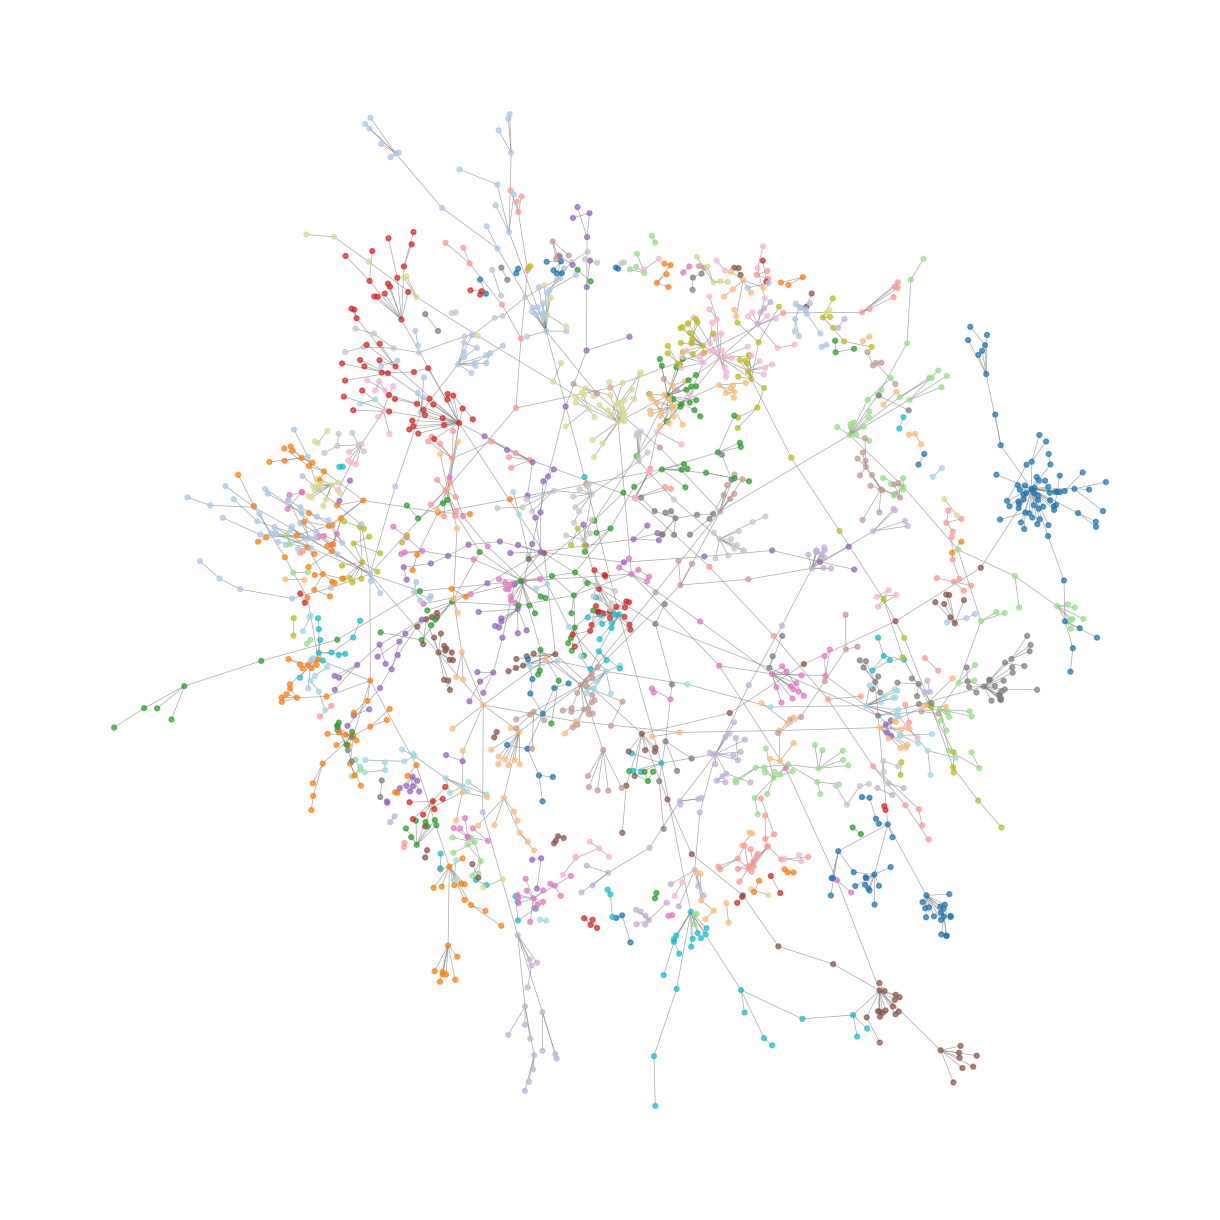

In [17]:
pos = nx.spring_layout(G, seed=42)

# One color per community
node_colors = [plt.cm.tab20(node_comm[n] % 20) for n in G.nodes()]

plt.figure(figsize=(12, 12))
nx.draw(G, pos, node_color=node_colors, node_size=12, width=0.5, edge_color="gray", alpha=0.7)
plt.show()

### 2.b

In [18]:
node_list = list(G.nodes())
index = {node: i for i, node in enumerate(node_list)} # original id > graph-tool index

g = gt.Graph(directed=False)           
g.add_vertex(len(node_list))                          
g.add_edge_list([(index[u], index[v]) for u, v in G.edges()]) # add the edges using the new indices

#check
print(g.num_vertices(), G.number_of_nodes())   
print(g.num_edges(), G.number_of_edges())     

1882 1882
1740 1740


In [19]:
gt.seed_rng(42) # seed = to make it reproducible
state = gt.minimize_blockmodel_dl(g) # fit the SBM that minimizes the description length
b = state.get_blocks() # community (block) of each node, by graph-tool index

In [20]:
# Partition
partition_gt = {node_list[i]: int(b[i]) for i in range(len(node_list))} # {node_id: community_id}

print('number of communities:', len(set(partition_gt.values()))) # how many groups the SBM found

number of communities: 1


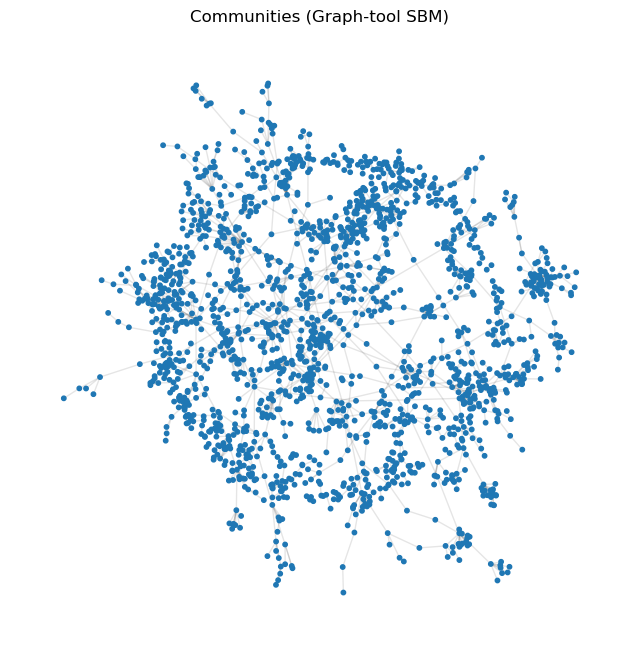

In [21]:

# Visualisation
colors = [partition_gt[node] for node in G.nodes()]   # community of each node, in networkx order

fig, ax = plt.subplots(figsize=(8, 8))
nx.draw_networkx_edges(G, pos, alpha=0.1, ax=ax)                            # edges, light so nodes are visible
nx.draw_networkx_nodes(G, pos, node_color=colors, cmap='tab20', node_size=10, ax=ax)   # nodes colored by community
ax.set_title('Communities (Graph-tool SBM)')
ax.axis('off')
plt.show()

### 2.c

In [22]:
# Randomization of the netwrok degree-preserving (edge-swap)

G_rand = G.copy()                             
n_swaps = 10 * G_rand.number_of_edges() # high number to assure the randomisation
nx.double_edge_swap(G_rand, nswap=n_swaps, max_tries=n_swaps * 100, seed=42)

# check
print('same degrees:', dict(G.degree()) == dict(G_rand.degree()))
print(G_rand)

same degrees: True
Graph with 1882 nodes and 1740 edges


In [23]:
# Louvian on the null model

communities_rand = nx.community.louvain_communities(G_rand, seed=42) 
Q_rand = nx.community.modularity(G_rand, communities_rand)  
partition_louvain_rand = {node: i for i, c in enumerate(communities_rand) for node in c}   # {node_id: community_id}

print('number of communities:', len(communities_rand))
print('modularity Q =', round(Q_rand, 4))

number of communities: 324
modularity Q = 0.8806


In [24]:
# SDM on the null model

def to_graph_tool(G):
    node_list = list(G.nodes())                             
    index = {node: i for i, node in enumerate(node_list)}
    g = gt.Graph(directed=False)
    g.add_vertex(len(node_list))
    g.add_edge_list([(index[u], index[v]) for u, v in G.edges()])
    return g, node_list

g_rand, node_list_rand = to_graph_tool(G_rand)

gt.seed_rng(42)                                           
state_rand = gt.minimize_nested_blockmodel_dl(g_rand) 
b_rand = state_rand.get_levels()[0].get_blocks() 

partition_sbm_rand = {node_list_rand[i]: int(b_rand[i]) for i in range(len(node_list_rand))} 

print('number of communities:', len(set(partition_sbm_rand.values())))

number of communities: 1


The modularity of the randomized network is still very high, even if this network has no real communities. This happens because the network is very sparse (average degree ca. 1.85), so it can be cut into many pieces by removing only a few edges. This means that the high modularity found in (a) is not enough to say that the original network has strong communities: the real network has only slightly more structure than the null model (0.96 vs 0.88). The SBM instead finds 1 group in both cases. With so few edges there is not enough evidence to justify more groups, so it does not find structure in the original network and, correctly, not even in the randomized one.

### 2.d

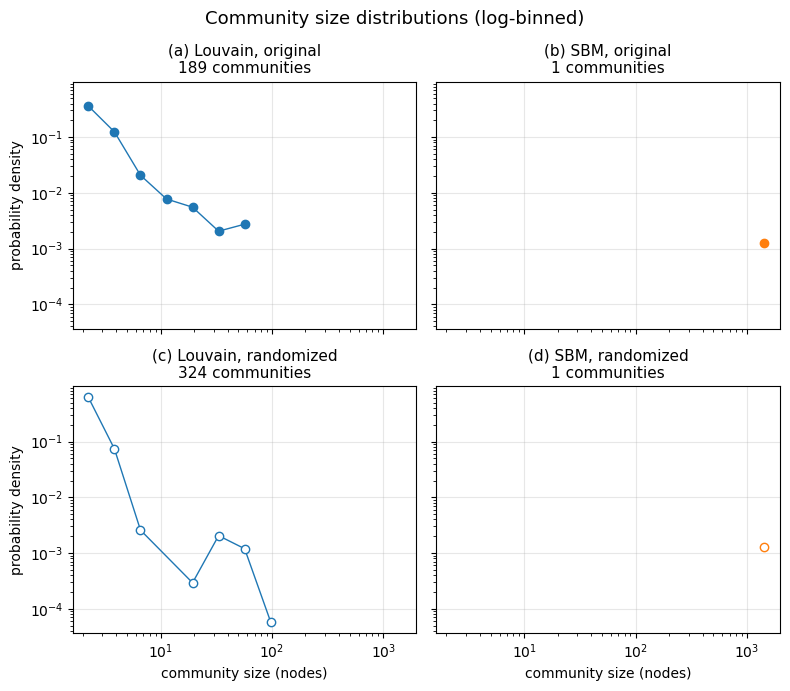

In [25]:
partitions = [partition, partition_gt, partition_louvain_rand, partition_sbm_rand]   # the four dictionaries
titles = ['(a) Louvain, original', '(b) SBM, original','(c) Louvain, randomized', '(d) SBM, randomized']
colors = ['C0', 'C1', 'C0', 'C1']          
filled = [True, True, False, False]          # filled = original, empty = randomized

# same log-spaced bins for all panels, from size 1 to the largest community
max_size = max(max(Counter(p.values()).values()) for p in partitions)
bins = np.logspace(0, np.log10(max_size + 1), 15)

fig, axes = plt.subplots(2, 2, figsize=(8, 7), sharex=True, sharey=True)   # same axes in all panels

for ax, part, title, color, full in zip(axes.flat, partitions, titles, colors, filled):
    sizes = list(Counter(part.values()).values())           # number of nodes in each community
    counts, edges = np.histogram(sizes, bins=bins)          # how many communities fall in each bin
    density = counts / (len(sizes) * np.diff(edges))        # divide by bin width -> probability density
    centers = np.sqrt(edges[:-1] * edges[1:])               # geometric center of each bin
    mask = counts > 0                                       # skip empty bins (can't plot 0 on log axes)

    ax.plot(centers[mask], density[mask], 'o-', color=color,
            markerfacecolor=color if full else 'white', markersize=6, linewidth=1)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(f'{title}\n{len(sizes)} communities', fontsize=11)
    ax.grid(True, which='major', alpha=0.3)

for ax in axes[1, :]:
    ax.set_xlabel('community size (nodes)')
for ax in axes[:, 0]:
    ax.set_ylabel('probability density')

fig.suptitle('Community size distributions (log-binned)', fontsize=13)
fig.tight_layout()
fig.savefig('community_size_distributions.pdf', dpi=300, bbox_inches='tight')
plt.show()


### 2.e

When we compare two partitions, the first problem is that the labels of the groups don’t mean anything. For example [0, 0, 1, 1] and [1, 1, 0, 0] are the same partition, only the names are different. So the function f can’t just compare the labels, it needs to compare how the nodes are grouped together.

I think a good f(b1, b2) should have some properties. If the two partitions are identical, f should give its maximum value (or 0 if f is a distance). It should be symmetric, so f(b1, b2) = f(b2, b1), and it should not change if I rename the groups. It should also work when the two partitions have a different number of groups. It would be useful if it is normalized, for example between 0 and 1, so I can compare results from different networks. Two random partitions should give a value close to “not similar”. Finally, it would be nice if f respects the triangle inequality, because then it is a real distance.

One of the most used methods in community detection is the Normalized Mutual Information (NMI), used for example by Danon et al. (2005) to compare different community detection algorithms. The idea is simple: if I know in which group a node is in b1, how much does it help me to know its group in b2? NMI uses the entropy H, which measures how uncertain a partition is, and the mutual information I(b1, b2), which measures how much information the two partitions share:

NMI(b1, b2) = 2 I(b1, b2) / [H(b1) + H(b2)]

If the partitions are the same, NMI = 1, and if they have nothing in common, NMI = 0. So it is symmetric, it doesn’t depend on the labels, it works with different numbers of groups and it is normalized.

But NMI also has some problems. It is not corrected for chance, so partitions with many small groups can have a high NMI even if they are similar only by chance. It is also not a real distance. Other methods fix some of these problems: the Variation of Information (Meilă, 2007) is a real distance, and the Adjusted Rand Index (Hubert & Arabie, 1985) is corrected for chance. In the end, no method has all the properties, so I would choose depending on what I want to compare.

Danon, L., Díaz-Guilera, A., Duch, J., & Arenas, A. (2005). Comparing community structure identification. Journal of Statistical Mechanics, P09008 (https://iopscience.iop.org/article/10.1088/1742-5468/2005/09/P09008).

Meilă, M. (2007). Comparing clusterings: an information based distance. Journal of Multivariate Analysis, 98(5), 873–895 (https://www.sciencedirect.com/science/article/pii/S0047259X06002016).

Hubert, L., & Arabie, P. (1985). Comparing partitions. Journal of Classification, 2(1), 193–218 (https://link.springer.com/article/10.1007/BF01908075). 

## Question 3 - Benchmarks for community detection

### 3.a.

The core motivation of the paper springs from a basic problem: to evaluate a community detection algorithm, you need to know the true communities in advance. In real networks this is rare, because reliable ground truth is seldom available and the few known examples are small. The standard benchmark at the time was the Girvan–Newman (GN) benchmark: 128 nodes divided into 4 communities of 32 nodes, with every node having the same expected degree (16). However, the GN benchmark has some limitations: all nodes have essentially the same degree, something real networks normally don't have (they tend to have heterogeneous, fat-tailed, often power-law degree distributions); all communities have the same size, whereas real networks often have communities of heterogeneous sizes; and the graph is very small (only 128 nodes). This is a limitation for evaluating algorithms: an algorithm could perform well on GN but poorly on real networks.

The LFR paper fills this gap. The authors introduce a class of benchmark graphs that generalizes the GN/planted-partition idea: both node degrees and community sizes follow power laws, so the benchmark reflects the heterogeneity seen in real networks. They also add a tunable "difficulty" parameter, the mixing parameter μ, which sets how clearly the communities are separated.

Inputs of the benchmark: the number of nodes (N), the average degree (⟨k⟩), the maximum degree (k_max), the exponent of the degree distribution (γ, typically 2–3), the exponent of the community size distribution (β, typically 1–2), the mixing parameter (μ, the fraction of each node's edges that go outside its community), and the minimum and maximum community sizes (s_min, s_max).

Outputs: an undirected, unweighted graph, and the planted community assignment (ground truth). The planted assignment is what makes it a benchmark: you run an algorithm on the graph, then compare its partition to the planted one.

### 3.b

#### 3.b.i

In [26]:
def powerlaw_degree_sequence(n, gamma, avg_k):
    k = np.random.pareto(gamma - 1, n) + 1  # power law P(k) ~ k^(-gamma)
    k = k * avg_k / k.mean() # rescale to the target average
    k = np.clip(np.round(k), 1, n - 1).astype(int)
    if k.sum() % 2 == 1: # configuration model needs an even sum
        k[0] += 1
    return k

#### 3.b.ii

In [27]:
def split_degrees(k, mu):
    k_in = np.round(k * (1 - mu)).astype(int) # edges inside the community
    k_out = k - k_in  # edges outside the community
    return k_in, k_out

#### 3.b.iii

In Step 3, community sizes are drawn from a power law with exponent β, but the paper notes two additional constraints.

First, the sizes of all communities must add up to the total number of nodes (N), so that every node belongs to exactly one community.

Second, the minimum and maximum community sizes must be compatible with the degree sequence: s_min must be larger than the minimum degree (k_min), and s_max must be larger than the maximum degree (k_max).

This ensures that every node, including the highest-degree hubs, can fit in at least one community, since a node needs enough other members in its community to connect to with its internal edges, k_in = k(1 − μ).

#### 3.b.iv

In [28]:
import numpy as np
import networkx as nx


# Step 1: power-law degree sequence
def powerlaw_degree_sequence(n, gamma, avg_k, k_max):
    k = np.random.pareto(gamma - 1, n) + 1
    for _ in range(20):                  # rescale and cap until the mean is right
        k = np.clip(k * avg_k / k.mean(), 1, k_max)
    return np.round(k).astype(int)


# Step 2: split each degree into internal and external parts
def split_degrees(k, mu):
    k_in = np.round(k * (1 - mu)).astype(int)
    return k_in, k - k_in


# Step 3: power-law community sizes that sum to n
def community_sizes(n, beta, s_min, s_max):
    sizes = []
    while sum(sizes) < n:
        u = np.random.rand()
        a = 1 - beta
        s = (s_min**a + u * (s_max**a - s_min**a)) ** (1 / a)
        sizes.append(int(round(s)))
    sizes[-1] -= sum(sizes) - n          # trim the last one so the total is n
    if sizes[-1] < s_min:                # merge it if it became too small
        last = sizes.pop()
        sizes[-1] += last
    return sizes


# Step 4: assign nodes to communities
def assign_communities(k_in, sizes, max_iter=100000):
    members = [[] for _ in sizes]
    homeless = list(range(len(k_in)))
    for _ in range(max_iter):
        if not homeless:
            return members
        node = homeless.pop(np.random.randint(len(homeless)))
        c = np.random.randint(len(sizes))
        if k_in[node] < sizes[c]:                  # community big enough for this node
            members[c].append(node)
            if len(members[c]) > sizes[c]:         # community full: kick someone out
                homeless.append(members[c].pop(np.random.randint(len(members[c]))))
        else:
            homeless.append(node)
    raise RuntimeError("Could not assign all nodes; check s_min, s_max and mu.")


# Helper: pair up stubs at random (configuration model)
def pair_stubs(stubs):
    np.random.shuffle(stubs)
    return list(zip(stubs[0::2], stubs[1::2]))


# Step 5: wire internal and external edges
def lfr_benchmark(n, gamma, beta, avg_k, k_max, mu, s_min, s_max, seed=None):
    if k_max >= s_max:
        raise ValueError("s_max must be larger than k_max (see Step 3).")
    np.random.seed(seed)
    k = powerlaw_degree_sequence(n, gamma, avg_k, k_max)
    k_in, k_out = split_degrees(k, mu)
    sizes = community_sizes(n, beta, s_min, s_max)
    while max(sizes) <= k_in.max():      # the biggest hub needs a big enough community
        sizes = community_sizes(n, beta, s_min, s_max)
    members = assign_communities(k_in, sizes)

    partition = {node: c for c, nodes in enumerate(members) for node in nodes}
    G = nx.Graph()
    G.add_nodes_from(range(n))

    # Internal edges: configuration model inside each community
    for nodes in members:
        stubs = [v for v in nodes for _ in range(k_in[v])]
        G.add_edges_from(pair_stubs(stubs))

    # External edges: configuration model on the whole graph,
    # re-shuffling stubs that end up inside the same community
    stubs = [v for v in range(n) for _ in range(k_out[v])]
    for _ in range(20):
        bad = []
        for u, v in pair_stubs(stubs):
            if partition[u] != partition[v]:
                G.add_edge(u, v)
            else:
                bad += [u, v]
        stubs = bad
        if len(stubs) < 2:
            break

    G.remove_edges_from(nx.selfloop_edges(G))
    nx.set_node_attributes(G, partition, "community")
    return G, partition


if __name__ == "__main__":
    G, partition = lfr_benchmark(n=1000, gamma=2.5, beta=1.5, avg_k=10,
                                 k_max=50, mu=0.2, s_min=20, s_max=100, seed=42)

    external = sum(partition[u] != partition[v] for u, v in G.edges())
    print(f"nodes: {G.number_of_nodes()}, edges: {G.number_of_edges()}")
    print(f"communities: {len(set(partition.values()))}")
    print(f"average degree: {2 * G.number_of_edges() / G.number_of_nodes():.2f}")
    print(f"measured mu: {external / G.number_of_edges():.3f}")

    # Sanity check: can Louvain recover the planted communities?
    from sklearn.metrics import normalized_mutual_info_score
    found = nx.community.louvain_communities(G, seed=42)
    found_partition = {v: c for c, nodes in enumerate(found) for v in nodes}
    nodes = list(G.nodes())
    nmi = normalized_mutual_info_score([partition[v] for v in nodes],
                                       [found_partition[v] for v in nodes])
    print(f"NMI (planted vs Louvain): {nmi:.3f}")

nodes: 1000, edges: 4381
communities: 19
average degree: 8.76
measured mu: 0.227
NMI (planted vs Louvain): 0.991


### 3.c

In [29]:
# Baseline parameters: a combination that usually works.
# max_degree < max_community, as the paper requires (k_max < s_max).
base = dict(n=500,            # number of nodes
            tau1=2.5,         # degree exponent (gamma in the paper)
            tau2=1.5,         # community size exponent (beta in the paper)
            mu=0.2,           # mixing parameter
            average_degree=10,
            max_degree=50,
            min_community=20,
            max_community=100)

def try_lfr(seed, **params):
    try:
        nx.LFR_benchmark_graph(seed=seed, **params)   # try to build one graph
        return "ok"                                   # it converged
    except nx.ExceededMaxIterations as e:             # it gave up after max_iters attempts
        return str(e)                                 # the message says which step failed

In [30]:
# Values to test for each parameter (one changes at a time, the others stay at the baseline)
sweeps = {
    "mu": [0.05, 0.2, 0.5, 0.7],
    "tau1": [2.1, 2.5, 3.0, 3.5],
    "average_degree": [5, 10, 20, 40],
    "max_degree": [20, 50, 90, 200],
    "min_community": [10, 20, 50, 80],
}

for name, values in sweeps.items():                     # go through each parameter
    for v in values:                                    # go through each value of that parameter
        params = {**base, name: v}                      # copy the baseline and change only this parameter
        outcomes = [try_lfr(s, **params) for s in range(10)]   # 10 runs with different seeds
        print(name, v, Counter(outcomes))               # how many "ok" and which errors

mu 0.05 Counter({'ok': 10})
mu 0.2 Counter({'ok': 10})
mu 0.5 Counter({'ok': 10})
mu 0.7 Counter({'ok': 10})
tau1 2.1 Counter({'ok': 10})
tau1 2.5 Counter({'ok': 10})
tau1 3.0 Counter({'ok': 10})
tau1 3.5 Counter({'ok': 10})
average_degree 5 Counter({'ok': 10})
average_degree 10 Counter({'ok': 10})
average_degree 20 Counter({'ok': 10})
average_degree 40 Counter({'Could not match average_degree': 10})
max_degree 20 Counter({'Could not match average_degree': 10})
max_degree 50 Counter({'ok': 10})
max_degree 90 Counter({'ok': 9, 'Could not assign communities; try increasing min_community': 1})
max_degree 200 Counter({'Could not assign communities; try increasing min_community': 8, 'ok': 2})
min_community 10 Counter({'ok': 10})
min_community 20 Counter({'ok': 10})
min_community 50 Counter({'ok': 10})
min_community 80 Counter({'ok': 5, 'Could not create power law sequence': 5})


I started from a baseline that always worked (n = 500, γ = 2.5, β = 1.5, µ = 0.2, ⟨k⟩ = 10, k_max = 50, s_min = 20, s_max = 100) and changed one parameter at a time, running each value with 10 different seeds. When a run failed I saved the error message, because it tells which step went wrong.

Changing µ or γ made no difference (10/10 every time). The other parameters made a big one, and I found three kinds of errors:

- "Could not create power law sequence": the community sizes are drawn at random until they add up exactly to n. With a large s_min (80) few combinations work, so half the runs failed. This one depends on luck, because with the same parameters some seeds work and others don't.

## Quesiton 4 - Python packages and software managment

### 4.a

My toolkit contains nine functions taken from code I already wrote in this and the previous assignment. They cover the full workflow of the assignment: generate a network, describe its degree distribution, build a null model, detect communities, and compare partitions.

| Step | Function | What it does |
|---|---|---|
| Generate | `grow_ba_network(N, m, seed)` | Grows a Barabási–Albert network by preferential attachment (targets-pool trick). |
| Generate | `powerlaw_degree_sequence(n, gamma, avg_k, k_max)` | Samples a power-law degree sequence with a target ⟨k⟩, a cap on k, and an even sum. |
| Generate | `lfr_benchmark(n, gamma, beta, avg_k, k_max, mu, s_min, s_max, seed)` | Generates an LFR graph with planted communities. The step helpers stay internal. |
| Describe | `log_binned_distribution(degrees, n_bins)` | Computes a log-binned pₖ with geometric bin centers. |
| Null model | `degree_preserving_null(G, swaps_per_edge)` | Randomizes the network with edge swaps, keeping all degrees. |
| Detect | `to_graph_tool(G)` | Converts a networkx graph to graph-tool and keeps the node mapping. |
| Detect | `louvain_partition(G, seed)` | Runs Louvain and returns `{node: community}` and Q. |
| Detect | `sbm_partition(G, nested)` | Fits a flat or nested SBM and returns `{node: block}`. |
| Evaluate | `compare_partitions(p1, p2)` | Computes the NMI between two partitions, independent of labels (see 2.e). |

I chose these because I either repeated the code several times (BA growth, log binning, partition dictionaries) or expect to reuse it in future projects. Both detection functions return the same `{node: id}` format, so their outputs plug directly into `compare_partitions`. Every function takes a `seed` for reproducibility.

### 4.b

Repository: https://github.com/JacopoConti/netsci_toolkit

The README explains what the package does and how to install it (`pip install -e .`, with graph-tool as an optional conda dependency). It includes a quick-start example, the package structure, and a reference for each of the nine functions: what it does, its parameters, what it returns, and a short usage example.

### 4.c

Following the pyOpenSci tutorials, I organized the code with a `src/` layout and a `pyproject.toml` (hatchling backend), so the package installs with `pip install -e .`. The functions are split into modules by workflow step:

| Module | Functions |
|---|---|
| `generators.py` | `grow_ba_network`, `powerlaw_degree_sequence`, `lfr_benchmark` (LFR step helpers kept private) |
| `degrees.py` | `log_binned_distribution` |
| `nullmodels.py` | `degree_preserving_null` |
| `communities.py` | `to_graph_tool`, `louvain_partition`, `sbm_partition`, `compare_partitions` |

`__init__.py` exposes all nine functions, so they can be called directly (e.g. `nt.lfr_benchmark(...)`). The repository also includes a small test file and an MIT license. I checked the installation by importing the package and recovering the planted LFR communities with Louvain (NMI ≈ 1).

In [31]:
%pip install git+https://github.com/JacopoConti/netsci_toolkit.git

  Cloning https://github.com/JacopoConti/netsci_toolkit.git to /private/var/folders/hz/8_pbd_z510s72pvrq_72td3c0000gn/T/pip-req-build-c774wruu
  Running command git clone --filter=blob:none --quiet https://github.com/JacopoConti/netsci_toolkit.git /private/var/folders/hz/8_pbd_z510s72pvrq_72td3c0000gn/T/pip-req-build-c774wruu
  Resolved https://github.com/JacopoConti/netsci_toolkit.git to commit 58b07b60276c135a3246f2250ca87ea6e294826e
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.


In [32]:
import netsci_toolkit as nt

G, planted = nt.lfr_benchmark(n=1000, gamma=2.5, beta=1.5, avg_k=10,
                              k_max=50, mu=0.2, s_min=20, s_max=100, seed=42)
found, Q = nt.louvain_partition(G, seed=42)
print(f"Q = {Q:.3f}, NMI = {nt.compare_partitions(planted, found):.3f}")

Q = 0.709, NMI = 0.999


### 4.d

Following the pyOpenSci tutorial, `pyproject.toml` is what makes the package pip installable. It declares the build backend (hatchling), the package metadata, the dependencies (numpy, networkx, scikit-learn), and an optional `test` extra with pytest.

Anyone can install it in two ways:

    git clone https://github.com/JacopoConti/netsci_toolkit.git
    cd netsci_toolkit
    pip install .

or directly from GitHub: `pip install git+https://github.com/JacopoConti/netsci_toolkit.git`

Then, in Python: `import netsci_toolkit as nt`

I tested this in a fresh conda environment (Python 3.11). The repository cloned, installed with all its dependencies, imported correctly, and passed all tests (`pytest`: 5 passed). The cells below install the package from GitHub into this notebook's kernel and use it to generate an LFR graph and recover its communities with Louvain.

Note: `to_graph_tool` and `sbm_partition` also require graph-tool, which is not available on pip and must be installed with `conda install -c conda-forge graph-tool`.